# Import data of possible binary AGN candidates

## Download published SMBH-binary candidate catalogues from VizieR

Catalogues:

    1. foustoul2025 (https://www.aanda.org/articles/aa/pdf/2025/07/aa52818-24.pdf)
    2. graham2015

In [ ]:
from astroquery.vizier import Vizier
from pathlib import Path

In [ ]:
# use Harvard vizier server, since strasbourg didnt work
vizier = Vizier(
    columns=["**"],
    row_limit=-1,
    vizier_server="vizier.cfa.harvard.edu",
    timeout=120
)

tables = vizier.get_catalogs(
    "J/A+A/699/A55/tablec1"
)

df = tables[0].to_pandas()

df = df.rename(columns={
    "Name": "ztf_oid",
    "RAJ2000": "ra",
    "DEJ2000": "dec",
    "Per": "period_days",
    "z": "redshift"
})

print(df.head())
print("Number of candidates:", len(df))

Path("data").mkdir(exist_ok=True)

df.to_csv(
    "../data/foustoul2025_weak_candidates.csv",
    index=False
)


   recno          ztf_oid        ra      dec  redshift  period_days  \
0      1  722214100002451  246.1833  43.9945      1.93  1517.199951   
1      2  762207400010289  253.4480  46.5943      2.29  1547.900024   
2      3  796215300002648  254.9410  57.5255      2.06  1354.800049   
3      4  721210400000714  237.5624  41.4187      1.89  1527.599976   
4      5  760213300014840  237.5921  49.7842      2.09  1545.900024   

        e_Per  logMBH  e_logMBH  rchi2 CRTSobs  
0   55.799999    9.24      0.02   1.09      No  
1  650.799988    8.12      0.15   1.23     Yes  
2   45.299999     NaN       NaN   0.92      No  
3  720.700012    8.82      0.05   1.22     Yes  
4  722.799988    8.69      0.08   1.03     Yes  
Number of candidates: 221


['oid', 'expid', 'hjd', 'mjd', 'mag', 'magerr', 'catflags', 'filtercode', 'ra', 'dec', 'chi', 'sharp', 'filefracday', 'field', 'ccdid', 'qid', 'limitmag', 'magzp', 'magzprms', 'clrcoeff', 'clrcounc', 'exptime', 'airmass', 'programid']
               oid     expid           hjd           mjd        mag    magerr  \
0  686203400035219  46348929  2.458218e+06  58217.489294  15.210025  0.018190   
1  686203400035219  46351206  2.458218e+06  58217.512060  15.214787  0.018195   
2  686203400035219  46449571  2.458219e+06  58218.495718  15.213990  0.018194   
3  686203400035219  46451202  2.458219e+06  58218.512026  15.188669  0.018167   
4  686203400035219  47545592  2.458230e+06  58229.455926  15.215181  0.018195   

   catflags filtercode          ra        dec  ...  ccdid  qid   limitmag  \
0         0         zr  298.002533  29.871466  ...    0x3  0x4  20.420000   
1         0         zr  298.002545  29.871460  ...    0x3  0x4  20.570000   
2         0         zr  298.002538  29.871479  

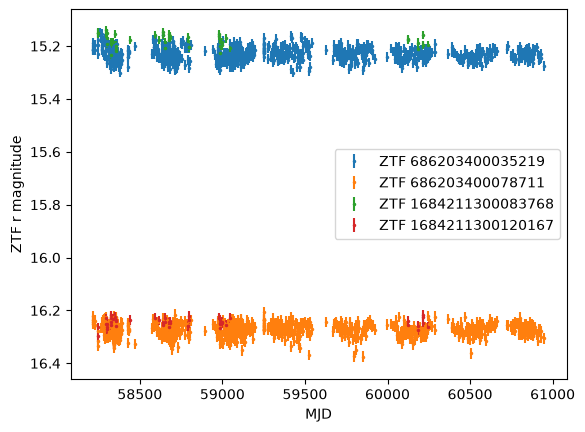

In [1]:

import requests
import pandas as pd
import matplotlib.pyplot as plt
from io import StringIO

# Example coordinates from the IRSA documentation
ra = 298.0025
dec = 29.87147

url = "https://irsa.ipac.caltech.edu/cgi-bin/ZTF/nph_light_curves"

params = {
    "POS": f"CIRCLE {ra} {dec} {5 / 3600}",
    "BANDNAME": "r",
    "BAD_CATFLAGS_MASK": 32768,
    "FORMAT": "CSV"
}

response = requests.get(url, params=params, timeout=120)
response.raise_for_status()

ztf = pd.read_csv(StringIO(response.text))

print(ztf.columns.tolist())
print(ztf.head())

# Save the original measurements
ztf.to_csv("ztf_lightcurve.csv", index=False)

# Plot each ZTF object ID separately
for oid, lc in ztf.groupby("oid"):
    plt.errorbar(
        lc["mjd"],
        lc["mag"],
        yerr=lc["magerr"],
        fmt=".",
        markersize=3,
        label=f"ZTF {oid}"
    )

plt.gca().invert_yaxis()
plt.xlabel("MJD")
plt.ylabel("ZTF r magnitude")
plt.legend()
plt.show()
